# Brain CT Dataset (AKMMCH + SSMC): Dataset Insights

This notebook profiles the patient-level annotation sheet (`All_patient_dataset.xlsx`) behind the **Dataset** section of the Attn-GAN low-dose brain CT paper, and checks it against the numbers stated in the manuscript.

**What the two inputs contain**

| Source | Content |
|---|---|
| `All_patient_dataset.xlsx` → `Sheet1` | 97 patients × 13 columns: ID, Normal/Abnormal, diagnostic class, 8 region-wise findings, intracerebral haemorrhage, impression |
| `All_patient_dataset.xlsx` → `Misc Demo` | 3 example patients (glioma, lipoma, calcified lesion), duplicated from `Sheet1` |
| Manuscript (Dataset section) | Per-class **slice** counts (12,018 slices), the report-based vs retrospective split (10 / 87 patients, 2,706 / 9,312 slices), and the noise-variance analysis |

The spreadsheet has no slice-level data, so slice counts are taken from the manuscript's Table (`tab:class_distribution`) and marked as such. The pixel-variance (noise) analysis needs the images themselves and can't be reproduced from these files.

**Contents**
1. Setup and loading
2. Structure and data quality
3. Cross-check against the manuscript
4. Class distribution and imbalance (patients and slices)
5. Annotation sources: report-based (CT) vs retrospective (WR)
6. Harmonising the findings vocabulary
7. Region-wise findings by class
8. What the "Normal" class actually contains
9. Laterality of focal lesions
10. Scan coverage and incomplete assessments
11. Implications for splitting and evaluation
12. Summary and suggested manuscript edits

## 1. Setup and loading

In [1]:
import re
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.colors import LinearSegmentedColormap

# Put the spreadsheet next to this notebook, or change the path.
DATA_PATH = "All_patient_dataset.xlsx"

pd.set_option("display.max_colwidth", 120)
pd.set_option("display.width", 200)

# Plot styling: thin marks, recessive axes, neutral text ink.
INK, INK_2, GRID = "#0b0b0b", "#52514e", "#e4e3df"
C_NORMAL, C_ABNORMAL = "#2a78d6", "#eb6834"      # categorical slots 1 and 2
C_LEFT, C_RIGHT, C_OTHER = "#2a78d6", "#eb6834", "#a3a29c"
SEQ_BLUE = LinearSegmentedColormap.from_list("seq_blue", ["#f4f8fd", "#a9c8ee", "#2a78d6", "#123f75"])

plt.rcParams.update({
    "figure.dpi": 110, "savefig.dpi": 110,
    "font.size": 10, "axes.titlesize": 11.5, "axes.titleweight": "bold", "axes.titlelocation": "left",
    "axes.labelcolor": INK_2, "text.color": INK, "xtick.color": INK_2, "ytick.color": INK_2,
    "axes.edgecolor": "#b9b8b2", "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "grid.color": GRID, "grid.linewidth": 0.8, "axes.axisbelow": True,
    "legend.frameon": False,
})

raw = pd.read_excel(DATA_PATH, sheet_name="Sheet1")
demo = pd.read_excel(DATA_PATH, sheet_name="Misc Demo")
print("Sheet1:", raw.shape, "| Misc Demo:", demo.shape)
display(raw.head(5))

Sheet1: (97, 13) | Misc Demo: (3, 12)


,Sl No.,Class Title,Class,CSF Spaces(L),CSF Spaces(R),Sulci,CP Angle,Scalp/Skull Bones,Fourth Venricle,Intracerebral Haemorrage,Ventricular System,Brainstem/Cerebellum,Impression
0,CT01,Abnormal,cortical_atrophy,Increased,N. Widened,Slightly Enlarged(L),Normal,Normal,Midline,NaN,Normal,No Abnormality,Left Cerebral Cortical Atrophy
1,CT02,Abnormal,cerebral_infarct,Small Irregular Hypo,N. Widened,NaN,Normal,Normal,Midline,NaN,Mildly Dialated(L),No Abnormality,Left Cerebral Infarct
2,CT03,Normal,Normal,N. Widened,N. Widened,Visible,Normal,Normal,Midline,NaN,Normal,No Abnormality,Normal
3,CT04,Abnormal,lipoma,N. Widened,N. Widened,Visible,Normal,Normal,Midline,NaN,Normal,No Abnormality,Lipoma
4,CT05,Abnormal,cerebral_infarct,Hypodensity (L temporal/insular),N. Widened,Visible,Normal,Normal,Midline,NaN,Mildly Prominent,No Abnormality,Cerebral Infarct


## 2. Structure and data quality

Before any analysis: column names, missing values, ID integrity, label spelling, and whether the `Misc Demo` sheet agrees with `Sheet1`.

In [2]:
profile = pd.DataFrame({
    "dtype": raw.dtypes.astype(str),
    "missing": raw.isna().sum(),
    "unique values": raw.nunique(),
    "most common": [raw[c].value_counts().index[0] if raw[c].notna().any() else None for c in raw.columns],
})
display(profile)

,dtype,missing,unique values,most common
Sl No.,str,0,97,CT01
Class Title,str,0,2,Normal
Class,str,0,8,Normal
CSF Spaces(L),str,0,11,Normal
CSF Spaces(R),str,0,8,Normal
Sulci,str,1,8,Normal
CP Angle,str,0,3,Normal
Scalp/Skull Bones,str,0,5,Normal
Fourth Venricle,str,0,3,Midline
Intracerebral Haemorrage,str,96,1,"Large haematoma, L basal ganglia, with intraventricular extension"


In [3]:
# Cleaned working copy: fix header typos and unify class-label spelling.
df = raw.rename(columns={
    "Sl No.": "ID", "Class Title": "Group",
    "CSF Spaces(L)": "CSF (L)", "CSF Spaces(R)": "CSF (R)",
    "Fourth Venricle": "Fourth Ventricle",
    "Intracerebral Haemorrage": "Intracerebral Haemorrhage",
}).copy()

CLASS_NAMES = {
    "normal": "Normal", "cerebral_infarct": "Cerebral Infarct", "glioma": "Glioma",
    "ischemic_changes": "Ischemic Changes", "cortical_atrophy": "Cortical Atrophy",
    "calcified_lesion": "Calcified Lesion", "intracerebral_haemorrhage": "Intracerebral Haemorrhage",
    "lipoma": "Lipoma",
}
print("Raw class spellings:", sorted(raw["Class"].unique()))
df["Class"] = df["Class"].str.strip().str.lower().map(CLASS_NAMES)
assert df["Class"].notna().all()

CLASS_ORDER = ["Normal", "Cerebral Infarct", "Glioma", "Ischemic Changes", "Cortical Atrophy",
               "Calcified Lesion", "Intracerebral Haemorrhage", "Lipoma"]   # manuscript table order
df["Class"] = pd.Categorical(df["Class"], CLASS_ORDER, ordered=True)

# ID structure: prefix = annotation source, number = patient serial.
df["Source"] = df["ID"].str[:2].map({"CT": "Report-based (CT)", "WR": "Retrospective (WR)"})
df["Serial"] = df["ID"].str[2:].astype(int)

print("Duplicate IDs:", df["ID"].duplicated().sum())
print("Group/Class agreement:",
      ((df["Group"] == "Normal") == (df["Class"] == "Normal")).all())
wr_serials = set(df.loc[df["ID"].str.startswith("WR"), "Serial"])
ct_serials = set(df.loc[df["ID"].str.startswith("CT"), "Serial"])
missing_wr = sorted(set(range(1, max(wr_serials) + 1)) - wr_serials)
print("WR serials not present:", missing_wr)
print("  ...of which used by a CT patient:", sorted(set(missing_wr) & ct_serials))
print("  ...unaccounted for:", sorted(set(missing_wr) - ct_serials))

Raw class spellings: ['Glioma', 'Intracerebral_haemorrhage', 'Ischemic_changes', 'Normal', 'calcified_lesion', 'cerebral_infarct', 'cortical_atrophy', 'lipoma']
Duplicate IDs: 0
Group/Class agreement: True
WR serials not present: [35, 61, 71, 78]
  ...of which used by a CT patient: [61, 71, 78]
  ...unaccounted for: [35]


In [4]:
# Does the 'Misc Demo' sheet match Sheet1 for the same patients?
demo_c = demo.rename(columns={"Sl No.": "ID", "CSF Spaces(L)": "CSF (L)", "CSF Spaces(R)": "CSF (R)",
                              "Fourth Venricle": "Fourth Ventricle",
                              "Intracerebral Haemorrage": "Intracerebral Haemorrhage"})
mismatches = []
for _, r in demo_c.iterrows():
    s = df.loc[df["ID"] == r["ID"]].iloc[0]
    for col in demo_c.columns.drop(["ID", "Class"]):
        a, b = r[col], s[col]
        if not (pd.isna(a) and pd.isna(b)) and a != b:
            mismatches.append((r["ID"], col, a, b))
print(f"Misc Demo rows: {len(demo_c)} ({', '.join(demo_c['ID'])}); field mismatches vs Sheet1: {len(mismatches)}")

Misc Demo rows: 3 (WR54, CT04, WR31); field mismatches vs Sheet1: 0


**Data-quality notes**

- **IDs are clean.** 97 unique IDs, no duplicates, and `Class Title` (Normal/Abnormal) agrees with `Class` for every patient.
- **One serial number is missing.** WR serials 61, 71 and 78 are absent because those numbers belong to CT61, CT71 and CT78, but **WR35** has no counterpart anywhere. It's worth checking whether a patient was excluded (and why), since a reviewer may ask about exclusions.
- **Header and label spelling.** `Fourth Venricle`, `Intracerebral Haemorrage` and `Mildly Dialated` are typos, and class labels mix cases (`Glioma`, `lipoma`, `Intracerebral_haemorrhage`). They are fixed in the working copy here; fix them at source before any table or figure from this sheet goes into the paper.
- **Missing values.** The only real gap is one blank `Sulci` cell (CT02). `Intracerebral Haemorrhage` is blank for 96 of 97 patients (section 10).
- `Misc Demo` is a faithful copy of three `Sheet1` rows, so it adds no new data.

## 3. Cross-check against the manuscript

Patient counts come from the spreadsheet. Slice counts are only in the manuscript, so they are entered here by hand and checked for internal consistency.

In [5]:
# Slice counts as stated in the manuscript (Table tab:class_distribution and text).
SLICES = pd.Series({"Normal": 8521, "Cerebral Infarct": 2001, "Glioma": 162, "Ischemic Changes": 80,
                    "Cortical Atrophy": 71, "Calcified Lesion": 8, "Intracerebral Haemorrhage": 528,
                    "Lipoma": 647})
PAPER_PATIENTS = pd.Series({"Normal": 79, "Cerebral Infarct": 9, "Glioma": 3, "Ischemic Changes": 2,
                            "Cortical Atrophy": 1, "Calcified Lesion": 1, "Intracerebral Haemorrhage": 1,
                            "Lipoma": 1})
PAPER_SUBSETS = {"Report-based (CT)": (10, 2706), "Retrospective (WR)": (87, 9312)}

sheet_patients = df["Class"].value_counts().reindex(CLASS_ORDER)
check = pd.DataFrame({"patients (sheet)": sheet_patients, "patients (paper)": PAPER_PATIENTS,
                      "slices (paper)": SLICES})
check["match"] = check["patients (sheet)"] == check["patients (paper)"]
display(check)

src_counts = df["Source"].value_counts()
for src, (p, s) in PAPER_SUBSETS.items():
    print(f"{src}: sheet={src_counts[src]} patients, paper={p} patients / {s:,} slices")

total_slices = SLICES.sum()
print(f"\nSlices sum to {total_slices:,} (paper: 12,018) -> {total_slices == 12018}")
print(f"Subset slices sum to {sum(s for _, s in PAPER_SUBSETS.values()):,}")
print(f"Normal share of slices:   {SLICES['Normal'] / total_slices:.1%}  (paper: 70.9%)")
print(f"Normal share of patients: {sheet_patients['Normal'] / len(df):.1%}  (paper: 81.4%)")
print(f"Other classes, patients:  {len(df) - sheet_patients['Normal']} ({1 - sheet_patients['Normal'] / len(df):.1%})  (paper: 18 / 18.6%)")

,patients (sheet),patients (paper),slices (paper),match
Normal,79,79,8521,True
Cerebral Infarct,9,9,2001,True
Glioma,3,3,162,True
Ischemic Changes,2,2,80,True
Cortical Atrophy,1,1,71,True
Calcified Lesion,1,1,8,True
Intracerebral Haemorrhage,1,1,528,True
Lipoma,1,1,647,True


Report-based (CT): sheet=10 patients, paper=10 patients / 2,706 slices
Retrospective (WR): sheet=87 patients, paper=87 patients / 9,312 slices

Slices sum to 12,018 (paper: 12,018) -> True
Subset slices sum to 12,018
Normal share of slices:   70.9%  (paper: 70.9%)
Normal share of patients: 81.4%  (paper: 81.4%)
Other classes, patients:  18 (18.6%)  (paper: 18 / 18.6%)


Every patient count, subset size, total and percentage in the Dataset section agrees with the spreadsheet and with itself. The noise-level paragraph (variance 4,000–8,000 for 81.9% of slices, cortical-atrophy median 10,235) can only be checked against the images.

## 4. Class distribution and imbalance

In [6]:
dist = pd.DataFrame({"patients": sheet_patients, "slices": SLICES.reindex(CLASS_ORDER)})
dist["% patients"] = (dist["patients"] / dist["patients"].sum() * 100).round(1)
dist["% slices"] = (dist["slices"] / dist["slices"].sum() * 100).round(1)
dist["slices / patient"] = (dist["slices"] / dist["patients"]).round(1)
dist["imbalance vs Normal (slices)"] = (dist.loc["Normal", "slices"] / dist["slices"]).round(1)
display(dist)

ab = dist.drop("Normal")
print(f"Abnormal: {ab['patients'].sum()} patients ({ab['patients'].sum()/97:.1%}) but "
      f"{ab['slices'].sum():,} slices ({ab['slices'].sum()/total_slices:.1%})")
print(f"Lipoma + ICH (2 patients) = {SLICES['Lipoma'] + SLICES['Intracerebral Haemorrhage']:,} slices "
      f"({(SLICES['Lipoma'] + SLICES['Intracerebral Haemorrhage'])/total_slices:.1%} of all slices)")
print(f"Largest / smallest class: {dist['patients'].max()}:{dist['patients'].min()} by patients, "
      f"{dist['slices'].max():,}:{dist['slices'].min()} by slices")

,patients,slices,% patients,% slices,slices / patient,imbalance vs Normal (slices)
Normal,79,8521,81.4,70.9,107.9,1.0
Cerebral Infarct,9,2001,9.3,16.7,222.3,4.3
Glioma,3,162,3.1,1.3,54.0,52.6
Ischemic Changes,2,80,2.1,0.7,40.0,106.5
Cortical Atrophy,1,71,1.0,0.6,71.0,120.0
Calcified Lesion,1,8,1.0,0.1,8.0,1065.1
Intracerebral Haemorrhage,1,528,1.0,4.4,528.0,16.1
Lipoma,1,647,1.0,5.4,647.0,13.2


Abnormal: 18 patients (18.6%) but 3,497 slices (29.1%)
Lipoma + ICH (2 patients) = 1,175 slices (9.8% of all slices)
Largest / smallest class: 79:1 by patients, 8,521:8 by slices


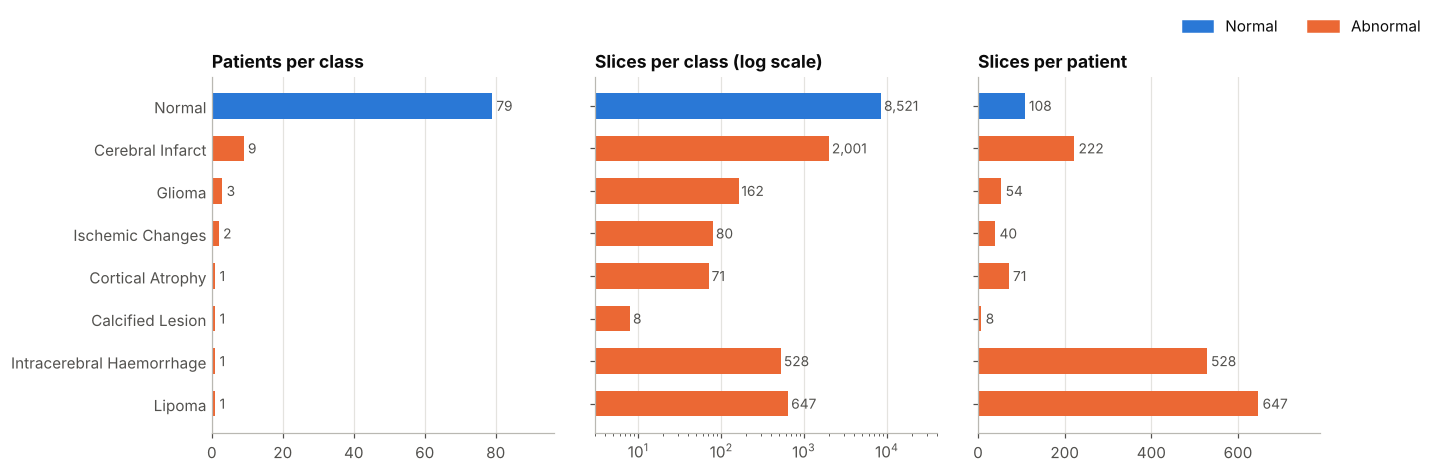

In [7]:
order = CLASS_ORDER[::-1]
colors = [C_NORMAL if c == "Normal" else C_ABNORMAL for c in order]
fig, axes = plt.subplots(1, 3, figsize=(13, 4.2), sharey=True, gridspec_kw={"wspace": 0.12})

panels = [("Patients per class", dist["patients"], "{:.0f}", False),
          ("Slices per class (log scale)", dist["slices"], "{:,.0f}", True),
          ("Slices per patient", dist["slices / patient"], "{:.0f}", False)]
for ax, (title, s, fmt, log) in zip(axes, panels):
    vals = s.reindex(order)
    ax.barh(order, vals, color=colors, height=0.6)
    if log:
        ax.set_xscale("log"); ax.set_xlim(3, 40000)
    else:
        ax.set_xlim(0, vals.max() * 1.22)
    for y, v in enumerate(vals):
        ax.text(v * (1.08 if log else 1) + (0 if log else vals.max() * 0.015), y, fmt.format(v),
                va="center", fontsize=9, color=INK_2)
    ax.set_title(title); ax.grid(axis="y", visible=False)
axes[0].tick_params(axis="y", length=0)
from matplotlib.patches import Patch
fig.legend(handles=[Patch(color=C_NORMAL, label="Normal"), Patch(color=C_ABNORMAL, label="Abnormal")],
           loc="upper right", ncol=2, bbox_to_anchor=(0.98, 1.04))
plt.show()

**What the distribution shows**

- **The imbalance is far steeper at slice level than the patient-level figure suggests at the tail.** Normal vs the smallest class is 79:1 by patients but about **1,065:1 by slices** (8,521 vs 8 calcified-lesion slices).
- **Abnormal data is over-represented by slices relative to patients.** The 18 abnormal patients are 18.6% of patients but 29.1% of slices, largely because two single-patient classes are very long series: lipoma (647 slices) and intracerebral haemorrhage (528). Those **two patients alone are 9.8% of all slices**.
- **Slices per patient vary 80-fold** (8 for the calcified lesion to 647 for the lipoma). This most likely reflects slice thickness/reconstruction protocol or how many slices were exported, not anatomy. It matters for the denoising work because any slice-level statistic, loss average or metric is dominated by whichever patients contributed the most slices.
- Four classes (cortical atrophy, calcified lesion, ICH, lipoma) contain a single patient. Anything reported "per class" for them, such as the cortical-atrophy noise median of 10,235, describes one scan rather than the condition.

## 5. Annotation sources: report-based (CT) vs retrospective (WR)

In [8]:
src_tab = pd.crosstab(df["Class"], df["Source"], margins=True, margins_name="Total")
display(src_tab)

sub = pd.DataFrame({k: {"patients": p, "slices (paper)": s, "slices / patient": round(s / p, 1)}
                    for k, (p, s) in PAPER_SUBSETS.items()}).T
display(sub)
lip_share = SLICES["Lipoma"] / PAPER_SUBSETS["Report-based (CT)"][1]
print(f"CT04 (lipoma) alone is {lip_share:.1%} of the report-based subset's slices.")

Source,Report-based (CT),Retrospective (WR),Total
Class,,,
Normal,5,74,79
Cerebral Infarct,2,7,9
Glioma,0,3,3
Ischemic Changes,1,1,2
Cortical Atrophy,1,0,1
Calcified Lesion,0,1,1
Intracerebral Haemorrhage,0,1,1
Lipoma,1,0,1
Total,10,87,97


,patients,slices (paper),slices / patient
Report-based (CT),10.0,2706.0,270.6
Retrospective (WR),87.0,9312.0,107.0


CT04 (lipoma) alone is 23.9% of the report-based subset's slices.


- The **10 report-based patients average about 271 slices each, against 107 for the 87 retrospectively annotated patients**, roughly 2.5×. The two subsets probably differ in acquisition or export protocol (thin vs thick reconstructions), not only in how labels were obtained. A sentence on slice thickness and scanner per subset would help readers, and it is a likely source of the per-slice noise differences.
- The report-based subset contributes 5 of 18 abnormal patients, including the only cortical-atrophy and lipoma cases. Those two classes therefore rest entirely on radiology reports, while glioma, ICH and the calcified lesion rest entirely on the retrospective review.

## 6. Harmonising the findings vocabulary

The two subsets use different words for the same thing. The report-based rows say `N. Widened` (not widened) and `Visible` where the retrospective rows say `Normal`. Each region-wise finding is mapped to a small common vocabulary so the subsets can be compared.

In [9]:
REGION_COLS = ["CSF (L)", "CSF (R)", "Sulci", "CP Angle", "Fourth Ventricle", "Brainstem/Cerebellum"]

def normalise_finding(v):
    if pd.isna(v):
        return "Not recorded"
    s = str(v).strip().lower()
    if "not assess" in s or "not visible" in s:
        return "Not assessable"
    if s in {"normal", "n. widened", "visible", "preserved", "patent", "midline", "no abnormality"}:
        return "Normal"
    if "hypo" in s:
        return "Hypodensity"
    if any(k in s for k in ("effaced", "decreased", "compress")):
        return "Effaced / compressed"
    if any(k in s for k in ("increased", "prominent", "enlarged", "dilat", "dialat")):
        return "Increased / prominent"
    return "Other: " + str(v)

norm = df[REGION_COLS].apply(lambda col: col.map(normalise_finding))

# Show what each raw term was mapped to, per subset (this is where CT and WR wording diverge).
mapping = (pd.concat([pd.DataFrame({"region": c, "raw": df[c].fillna("(blank)"), "normalised": norm[c],
                                    "source": df["Source"].str[-3:-1]}) for c in REGION_COLS])
             .groupby(["region", "raw", "normalised", "source"]).size().unstack(fill_value=0))
display(mapping)

source                                                                                                                   CT  WR
region               raw                                                                          normalised                   
Brainstem/Cerebellum Midbrain level is compressed                                                 Effaced / compressed    0   1
                     No Abnormality                                                               Normal                 10  80
                     Not assessable                                                               Not assessable          0   6
CP Angle             Normal                                                                       Normal                 10  77
                     Not assessable                                                               Not assessable          0   9
                     Patent                                                                       Normal                  0   1
CSF (L)              Diffusely effaced                                                            Effaced / compressed    0   1
                     Effaced/Decreased                                                            Effaced / compressed    0   2
                     Effaced/Decreased (L frontal)                                                Effaced / compressed    0   1
                     Effaced/Decreased (L frontoparietal)                                         Effaced / compressed    0   1
                     Hypodensity (L posterior temporo-parietal)                                   Hypodensity             0   1
                     Hypodensity (L temporal/insular)                                             Hypodensity             1   0
                     Hypodensity (L temporal/insular/temporo-occipital)                           Hypodensity             0   1
                     Increased                                                                    Increased / prominent   3  22
                     N. Widened                                                                   Normal                  5   0
                     Normal                                                                       Normal                  0  58
                     Small Irregular Hypo                                                         Hypodensity             1   0
CSF (R)              Compressed towards right due to mass effect                                  Effaced / compressed    0   1
                     Hypodensity (R temporal/insular/temporo-parietal)                            Hypodensity             0   1
                     Increased                                                                    Increased / prominent   2  20
                     Increased (R Sylvian fissure and posterior perisylvian sulci more prominent) Increased / prominent   0   1
                     Increased (R Sylvian fissure more prominent)                                 Increased / prominent   0   1
                     N. Widened                                                                   Normal                  8   0
                     Normal                                                                       Normal                  0  61
                     Preserved                                                                    Normal                  0   2
Fourth Ventricle     Midline                                                                      Normal                 10  78
                     Not Visible                                                                  Not assessable          0   1
                     Not assessable                                                               Not assessable          0   8
Sulci                (blank)                                                                      Not recorded            1   0
                     Effaced (L)

In [10]:
# Ventricular system is free text: extract flags instead.
vs = df["Ventricular System"].str.lower()
df["VS incomplete"] = vs.str.contains("can not assess|cannot assess")
df["VS benign calcification"] = vs.str.contains("calcif")
df["VS prominent/dilated"] = vs.str.contains("prominent|dilat|dialat")
df["VS compressed/shift"] = vs.str.contains(r"compress|rightward|leftward|shift of")
print(df[["VS incomplete", "VS benign calcification", "VS prominent/dilated", "VS compressed/shift"]].sum())

VS incomplete              19
VS benign calcification    48
VS prominent/dilated       20
VS compressed/shift         4
dtype: int64


After mapping, the CT and WR wording lines up on the same categories. Two practical points:

- If these labels are released with the dataset or used as auxiliary targets, store the **normalised vocabulary** (or a controlled list) rather than the free text; the raw column `Ventricular System` alone has 37 distinct strings for 97 patients.
- **Benign pineal/choroid-plexus calcification** is noted in many ventricular-system entries. These are bright, high-contrast structures, so they are a useful check that denoising preserves small hyperdense detail.

## 7. Region-wise findings by class

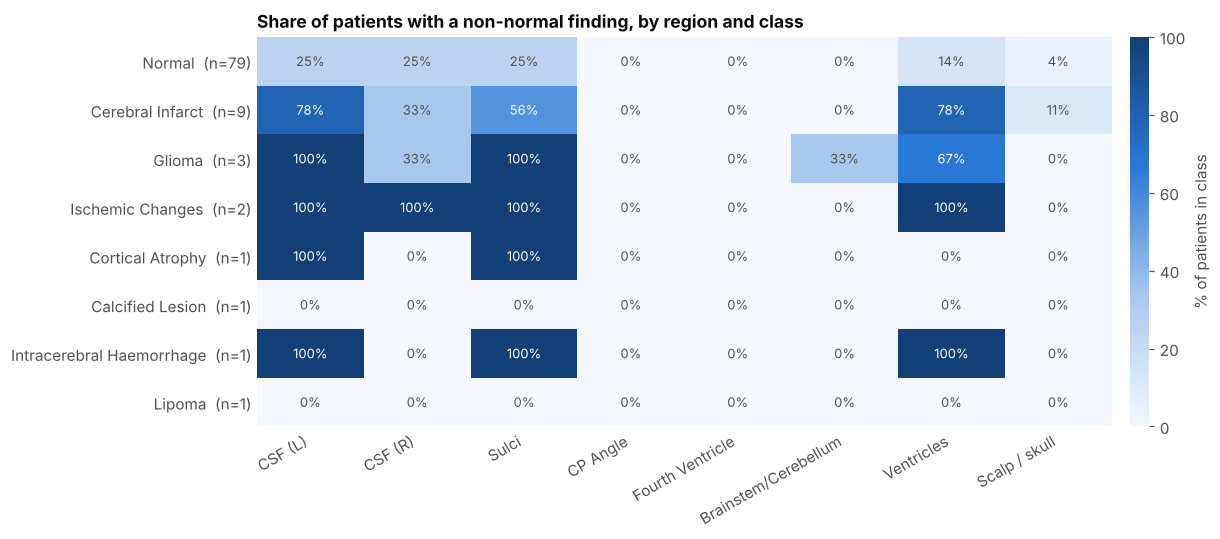

,CSF (L),CSF (R),Sulci,CP Angle,Fourth Ventricle,Brainstem/Cerebellum,Ventricles,Scalp / skull
Class,,,,,,,,
Normal,25.0,25.0,25.0,0.0,0.0,0.0,14.0,4.0
Cerebral Infarct,78.0,33.0,56.0,0.0,0.0,0.0,78.0,11.0
Glioma,100.0,33.0,100.0,0.0,0.0,33.0,67.0,0.0
Ischemic Changes,100.0,100.0,100.0,0.0,0.0,0.0,100.0,0.0
Cortical Atrophy,100.0,0.0,100.0,0.0,0.0,0.0,0.0,0.0
Calcified Lesion,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
Intracerebral Haemorrhage,100.0,0.0,100.0,0.0,0.0,0.0,100.0,0.0
Lipoma,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0


In [11]:
abn_rate = pd.concat({c: norm[c].isin(["Hypodensity", "Effaced / compressed", "Increased / prominent"])
                      for c in REGION_COLS}, axis=1)
abn_rate["Ventricles"] = df["VS prominent/dilated"] | df["VS compressed/shift"]
abn_rate["Scalp / skull"] = df["Scalp/Skull Bones"].str.lower().ne("normal")
abn_rate["Class"] = df["Class"]
heat = abn_rate.groupby("Class", observed=True).mean() * 100
n_per_class = df["Class"].value_counts().reindex(CLASS_ORDER)

fig, ax = plt.subplots(figsize=(10.5, 4.6))
im = ax.imshow(heat.values, cmap=SEQ_BLUE, vmin=0, vmax=100, aspect="auto")
ax.set_xticks(range(heat.shape[1]), heat.columns, rotation=30, ha="right")
ax.set_yticks(range(heat.shape[0]), [f"{c}  (n={n_per_class[c]})" for c in heat.index])
ax.grid(False); ax.tick_params(length=0)
for sp in ax.spines.values(): sp.set_visible(False)
for i in range(heat.shape[0]):
    for j in range(heat.shape[1]):
        v = heat.values[i, j]
        ax.text(j, i, f"{v:.0f}%", ha="center", va="center", fontsize=8.5,
                color="white" if v >= 55 else INK_2)
ax.set_title("Share of patients with a non-normal finding, by region and class")
cb = fig.colorbar(im, ax=ax, fraction=0.025, pad=0.02); cb.outline.set_visible(False)
cb.set_label("% of patients in class")
plt.show()
display(heat.round(0))

- **CSF spaces and sulci separate the classes most.** Increased CSF/prominent sulci mark atrophy and ischaemic change; effacement marks space-occupying lesions (glioma, ICH, the acute left MCA infarct WR01); focal hypodensity marks established infarcts.
- **The posterior fossa (CP angle, fourth ventricle, brainstem/cerebellum) is almost never abnormal.** The only positive is WR79 (glioma with midbrain compression). Non-normal values there are almost all "not assessable" (section 10).
- **Lipoma and the calcified lesion leave no trace in the region columns**; they are described only in the impression. The structured fields capture CSF/ventricular changes well but not focal lesions that don't displace CSF, so the impression text is the only record of where those lesions are.
- **A quarter of Normal patients (20 of 79) show increased CSF spaces/prominent sulci**, the same pattern as the ischaemic-change and atrophy classes. Section 8 looks at this directly.

## 8. What the "Normal" class actually contains

,patients
Impression type,
Normal (no findings),53
Age-related involutional change,23
No intracranial abnormality + extracranial finding,3


Within Normal class:
  Incidental focus (PVS vs lacune): 2  (WR13, WR41)
  Periventricular low attenuation: 1  (CT71)
  Generalised atrophy: 3  (WR47, WR49, WR72)


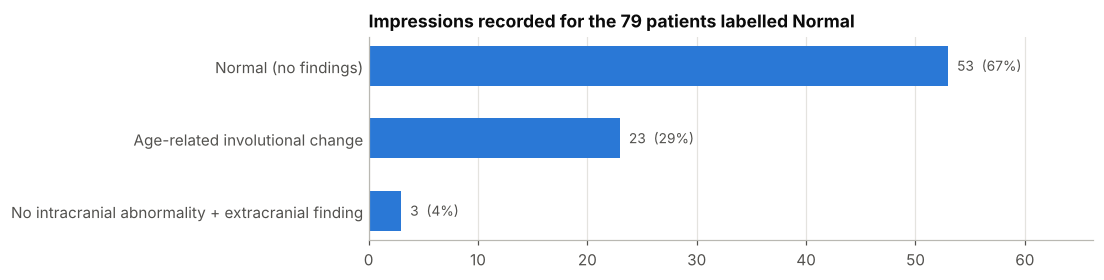

In [12]:
normal = df[df["Class"] == "Normal"].copy()
imp = normal["Impression"].str.lower()
normal["Impression type"] = np.select(
    [imp.str.strip().eq("normal"),
     imp.str.contains("scalp|extracranial"),
     imp.str.contains(r"involutional|atroph|age.related")],
    ["Normal (no findings)", "No intracranial abnormality + extracranial finding",
     "Age-related involutional change"],
    default="Other")
normal["Incidental focus (PVS vs lacune)"] = imp.str.contains("perivascular|lacune")
normal["Periventricular low attenuation"] = imp.str.contains("periventricular")
normal["Generalised atrophy"] = imp.str.contains("generalised cerebral atrophy")

comp = normal["Impression type"].value_counts()
display(comp.to_frame("patients"))
print("Within Normal class:")
for f in ["Incidental focus (PVS vs lacune)", "Periventricular low attenuation", "Generalised atrophy"]:
    print(f"  {f}: {normal[f].sum()}  ({', '.join(normal.loc[normal[f], 'ID'])})")

fig, ax = plt.subplots(figsize=(8.5, 2.4))
vals = comp.sort_values()
ax.barh(vals.index, vals.values, color=C_NORMAL, height=0.55)
for y, v in enumerate(vals.values):
    ax.text(v + 0.8, y, f"{v}  ({v/len(normal):.0%})", va="center", fontsize=9, color=INK_2)
ax.set_xlim(0, vals.max() * 1.25); ax.grid(axis="y", visible=False); ax.tick_params(axis="y", length=0)
ax.set_title(f"Impressions recorded for the {len(normal)} patients labelled Normal")
plt.show()

In [13]:
# Boundary cases: similar impressions, different class labels.
boundary_ids = ["CT01", "CT61", "WR53", "CT71", "WR47", "WR49", "WR72"]
display(df.set_index("ID").loc[boundary_ids, ["Class", "Source", "CSF (L)", "CSF (R)", "Sulci", "Impression"]])

,Class,Source,CSF (L),CSF (R),Sulci,Impression
ID,,,,,,
CT01,Cortical Atrophy,Report-based (CT),Increased,N. Widened,Slightly Enlarged(L),Left Cerebral Cortical Atrophy
CT61,Ischemic Changes,Report-based (CT),Increased,Increased,Prominent,Chronic small vessel ischaemic changes with mild cerebral involutional changes
WR53,Ischemic Changes,Retrospective (WR),Increased,Increased,Prominent,Chronic small vessel ischaemic changes (periventricular white matter hypodensity) with cerebral involutional changes
CT71,Normal,Report-based (CT),Increased,Increased,Prominent,Mild age-related involutional changes with periventricular low attenuation
WR47,Normal,Retrospective (WR),Increased,Increased,Prominent,Age-related cerebral involutional changes (generalised cerebral atrophy)
WR49,Normal,Retrospective (WR),Increased,Increased,Prominent,Moderate age-related cerebral involutional changes (generalised cerebral atrophy)
WR72,Normal,Retrospective (WR),Increased,Increased,Prominent,Moderate age-related cerebral involutional changes (generalised cerebral atrophy)


**"Normal" here means "no focal or acute intracranial pathology", not "no findings."**

- Only **53 of the 79 Normal patients (67%)** have a plain "Normal" impression. **23** have age-related involutional change (mild in most, moderate or generalised atrophy in 3), and **3** have an extracranial finding only (scalp swelling or haematoma).
- **The class boundaries are soft in two places:**
  - *Atrophy:* CT01 (*left cerebral cortical atrophy*) is its own class, while WR47, WR49 and WR72 with *generalised cerebral atrophy* are Normal.
  - *Small-vessel change:* CT61 and WR53 (*chronic small-vessel ischaemic changes*) are Ischemic Changes, while CT71 (*involutional change with periventricular low attenuation*) is Normal. WR13 and WR41 have tiny foci read as "perivascular space vs lacune" and are also Normal.
- For the denoising paper this mostly doesn't affect results, but it is worth one sentence in the Dataset section defining "normal" (for example, "no acute or focal intracranial abnormality; age-related involutional change was included in the normal class"). If the labels are ever used for classification, these cases should be reviewed or treated as a separate "age-related change" group.

## 9. Laterality of focal lesions

In [14]:
def side_from_text(t):
    t = str(t).lower()
    left, right = bool(re.search(r"\bleft\b", t)), bool(re.search(r"\bright\b", t))
    return "Left" if left and not right else "Right" if right and not left else ("Both" if left else None)

abn = df[df["Class"] != "Normal"].copy()
abn["Side"] = abn["Impression"].map(side_from_text)
# Fallback: side-tagged focal finding in the CSF/sulci columns, e.g. "Hypodensity (L temporal/insular)".
for i, r in abn[abn["Side"].isna()].iterrows():
    focal = " ".join(str(r[c]) for c in ["CSF (L)", "CSF (R)", "Sulci"])
    if re.search(r"\(L\b|\(L\)", focal):
        abn.loc[i, "Side"] = "Left"
    elif re.search(r"\(R\b|\(R\)", focal):
        abn.loc[i, "Side"] = "Right"
    elif r["Class"] == "Ischemic Changes":
        abn.loc[i, "Side"] = "Bilateral / diffuse"
abn["Side"] = abn["Side"].fillna("Not specified")

side_tab = pd.crosstab(abn["Class"], abn["Side"]).reindex(columns=["Left", "Right", "Bilateral / diffuse", "Not specified"], fill_value=0)
side_tab = side_tab.loc[side_tab.sum(axis=1) > 0]
display(side_tab)
display(abn[["ID", "Class", "Side", "Impression"]].sort_values(["Side", "Class"]).reset_index(drop=True))

# Scalp findings (all in Normal or infarct patients)
scalp = df[df["Scalp/Skull Bones"].str.lower() != "normal"][["ID", "Class", "Scalp/Skull Bones"]]
display(scalp)

Side,Left,Right,Bilateral / diffuse,Not specified
Class,,,,
Cerebral Infarct,5,4,0,0
Glioma,3,0,0,0
Ischemic Changes,0,0,2,0
Cortical Atrophy,1,0,0,0
Calcified Lesion,0,1,0,0
Intracerebral Haemorrhage,1,0,0,0
Lipoma,0,0,0,1


,ID,Class,Side,Impression
0,CT61,Ischemic Changes,Bilateral / diffuse,Chronic small vessel ischaemic changes with mild cerebral involutional changes
1,WR53,Ischemic Changes,Bilateral / diffuse,Chronic small vessel ischaemic changes (periventricular white matter hypodensity) with cerebral involutional changes
2,CT02,Cerebral Infarct,Left,Left Cerebral Infarct
3,CT05,Cerebral Infarct,Left,Cerebral Infarct
4,WR01,Cerebral Infarct,Left,Left MCA infarct
5,WR32,Cerebral Infarct,Left,"Large chronic left MCA territory infarct (temporal, insular, posterior temporo-parietal) with left occipital (PCA territory) involvement; encephalomalacia, no mass effect"
6,WR73,Cerebral Infarct,Left,Chronic left posterior temporo-parietal (MCA territory) infarct with encephalomalacia and ex vacuo dilatation of left lateral ventricle; no mass effect
7,WR54,Glioma,Left,"Left frontoparietal subcortical ring-enhancing lesion with surrounding white matter (vasogenic) oedema, mild local mass effect, no midline shift (DDx: glioma, metastasis, abscess; subacute infarct less likely)"
8,WR66,Glioma,Left,"Left frontal cortical-subcortical hypodense lesion with finger-like vasogenic white matter oedema and mild mass effect (DDx: glioma, metastasis, abscess, subacute contusion)"
9,WR79,Glioma,Left,Left anterior Glioma


,ID,Class,Scalp/Skull Bones
14,WR05,Cerebral Infarct,R frontoparietal scalp soft tissue swelling; no obvious fracture
18,WR09,Normal,R parietal scalp soft tissue swelling; no obvious fracture
19,WR10,Normal,R temporal scalp/temporalis soft tissue swelling; no obvious fracture
38,WR29,Normal,R temporoparietal scalp haematoma/soft tissue swelling; no fracture on bone window


Lateralised lesions: 10 left vs 5 right; exact binomial two-sided p = 0.30


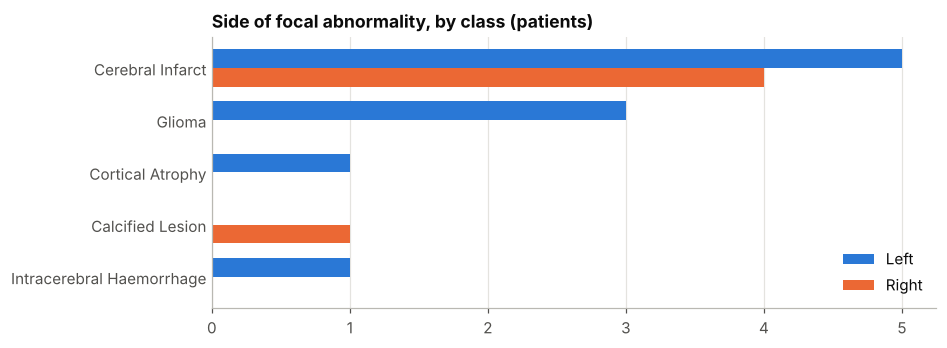

In [15]:
from math import comb
L, R = side_tab["Left"].sum(), side_tab["Right"].sum()
p_two_sided = min(1.0, 2 * sum(comb(L + R, k) for k in range(max(L, R), L + R + 1)) / 2 ** (L + R))
print(f"Lateralised lesions: {L} left vs {R} right; exact binomial two-sided p = {p_two_sided:.2f}")

plot_tab = side_tab[["Left", "Right"]].loc[lambda t: t.sum(axis=1) > 0].iloc[::-1]
fig, ax = plt.subplots(figsize=(8.5, 3.2))
y = np.arange(len(plot_tab)); h = 0.36
ax.barh(y + h/2, plot_tab["Left"], height=h, color=C_LEFT, label="Left")
ax.barh(y - h/2, plot_tab["Right"], height=h, color=C_RIGHT, label="Right")
ax.set_yticks(y, plot_tab.index); ax.tick_params(axis="y", length=0)
ax.xaxis.set_major_locator(plt.MaxNLocator(integer=True)); ax.grid(axis="y", visible=False)
ax.set_title("Side of focal abnormality, by class (patients)")
ax.legend(loc="lower right")
plt.show()

- Lateralised lesions are **10 left vs 5 right**. All three gliomas, the haemorrhage and the cortical atrophy are left-sided; infarcts are evenly split (5 left, 4 right). With 15 patients this is not a meaningful asymmetry (p ≈ 0.30), so it reflects case mix.
- All four scalp/soft-tissue swellings are on the **right**, three of them in Normal patients.
- **Practical consequence:** horizontal flipping is a safe augmentation for denoising and would balance the left-heavy lesion appearance. The test set will contain mostly left-sided pathology, so qualitative figures should include a right-sided example (e.g., WR42 or WR22).

## 10. Scan coverage and incomplete assessments

Patients with at least one incomplete region: 23 of 97


Source,Report-based (CT),Retrospective (WR)
Any incomplete,,
False,10,64
True,0,23


Class,Normal,Cerebral Infarct,Glioma,Ischemic Changes,Cortical Atrophy,Calcified Lesion,Intracerebral Haemorrhage,Lipoma
Any incomplete,,,,,,,,
False,57,9,3,2,1,0,1,1
True,22,0,0,0,0,1,0,0


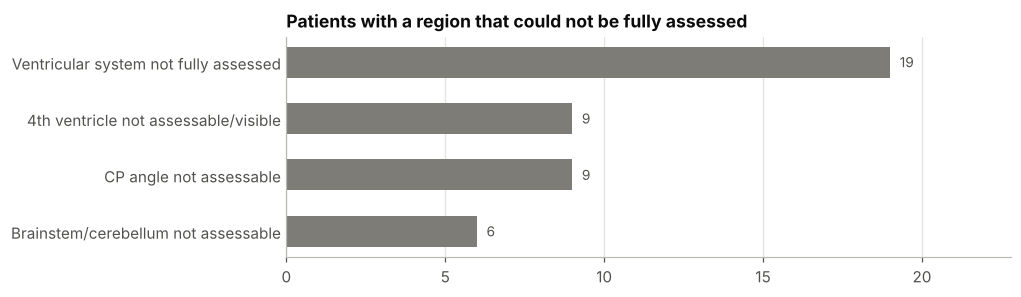

In [16]:
cov = pd.DataFrame({
    "CP angle not assessable": norm["CP Angle"].eq("Not assessable"),
    "4th ventricle not assessable/visible": norm["Fourth Ventricle"].eq("Not assessable"),
    "Brainstem/cerebellum not assessable": norm["Brainstem/Cerebellum"].eq("Not assessable"),
    "Ventricular system not fully assessed": df["VS incomplete"],
})
df["Any incomplete"] = cov.any(axis=1)
counts = cov.sum().sort_values()
print(f"Patients with at least one incomplete region: {df['Any incomplete'].sum()} of {len(df)}")
display(pd.crosstab(df["Any incomplete"], df["Source"]))
display(pd.crosstab(df["Any incomplete"], df["Class"]).loc[:, lambda t: t.sum() > 0])

fig, ax = plt.subplots(figsize=(8.5, 2.6))
ax.barh(counts.index, counts.values, color="#7d7c77", height=0.55)
for yy, v in enumerate(counts.values):
    ax.text(v + 0.3, yy, str(v), va="center", fontsize=9, color=INK_2)
ax.set_xlim(0, counts.max() * 1.2); ax.grid(axis="y", visible=False); ax.tick_params(axis="y", length=0)
ax.set_title("Patients with a region that could not be fully assessed")
plt.show()

In [17]:
ich = df["Intracerebral Haemorrhage"]
print(f"'Intracerebral Haemorrhage' column: {ich.notna().sum()} filled, {ich.isna().sum()} blank")
display(df.loc[ich.notna(), ["ID", "Class", "Intracerebral Haemorrhage"]])
mass = df[df["VS compressed/shift"] | norm[["CSF (L)", "CSF (R)", "Sulci"]].eq("Effaced / compressed").any(axis=1)]
print("Patients with effacement, compression or midline shift (mass effect):")
display(mass[["ID", "Class", "Ventricular System", "Brainstem/Cerebellum"]])

'Intracerebral Haemorrhage' column: 1 filled, 96 blank


,ID,Class,Intracerebral Haemorrhage
13,WR04,Intracerebral Haemorrhage,"Large haematoma, L basal ganglia, with intraventricular extension"


Patients with effacement, compression or midline shift (mass effect):


,ID,Class,Ventricular System,Brainstem/Cerebellum
10,WR01,Cerebral Infarct,Left lateral compression,No Abnormality
13,WR04,Intracerebral Haemorrhage,L lateral ventricle compressed with intraventricular blood; R relatively dilated,No Abnormality
62,WR54,Glioma,Normal; no significant midline shift,No Abnormality
73,WR66,Glioma,Normal; minimal rightward shift of septum pellucidum; benign choroid plexus calcifications,No Abnormality
84,WR79,Glioma,Rightward midline shift,Midbrain level is compressed


- **23 patients (24%), all from the retrospective WR subset (22 Normal plus the calcified-lesion case WR31), have at least one region marked "could not be assessed",** typically the ventricular system and/or the posterior fossa (CP angle, fourth ventricle, brainstem/cerebellum). Six lack all three posterior-fossa regions. These are almost certainly series that don't cover the whole brain, which fits the WR subset's lower slice count per patient.
- This is relevant to the noise analysis: if some series lack skull-base slices, slice-level intensity variance depends on *which part of the head* a series covers as well as on noise. When interpreting the variance histogram (e.g., the wide spread in the Normal class), it is worth checking variance against slice position or excluding near-empty top/bottom slices.
- **Haemorrhage column:** only WR04 has an entry; the other 96 cells are blank. The manuscript says "the presence or absence of intracerebral haemorrhage was noted for every patient." Either fill the blanks with "Absent" or reword the sentence.
- Five patients show mass effect (effacement, compression or midline shift): the three gliomas, the ICH and the acute left MCA infarct (WR01). These are the cases where denoising must not blur edges or soften oedema boundaries, so they make good qualitative test cases.

## 11. Implications for splitting and evaluation

In [18]:
# Which classes can appear in every split of a patient-level train/val/test split?
split_view = pd.DataFrame({"patients": sheet_patients, "slices": SLICES.reindex(CLASS_ORDER)})
split_view["can appear in train, val AND test"] = split_view["patients"] >= 3
split_view["note"] = np.where(split_view["patients"] == 1, "single patient: one split only",
                     np.where(split_view["patients"] == 2, "two patients: two splits at most", ""))
display(split_view)

,patients,slices,"can appear in train, val AND test",note
Normal,79,8521,True,
Cerebral Infarct,9,2001,True,
Glioma,3,162,True,
Ischemic Changes,2,80,False,two patients: two splits at most
Cortical Atrophy,1,71,False,single patient: one split only
Calcified Lesion,1,8,False,single patient: one split only
Intracerebral Haemorrhage,1,528,False,single patient: one split only
Lipoma,1,647,False,single patient: one split only


- **Split by patient, never by slice.** Adjacent axial slices from one patient are nearly identical. A slice-level random split puts near-duplicates in train and test, which inflates PSNR/SSIM. This matters most for the lipoma (647 slices) and ICH (528) patients.
- **Only Normal, Cerebral Infarct and Glioma have enough patients to appear in all three splits**; the four single-patient classes can only be in one. Report test-set metrics overall and separately for Normal vs Abnormal; per-class metrics for the singleton classes are case studies, not class estimates.
- **Weight metrics by patient, or report both.** Because slices per patient range from 8 to 647, a slice-averaged PSNR mostly reflects the long series. A patient-averaged metric (mean of per-patient means) is the fairer headline number.
- **Keep the report-based and retrospective subsets visible.** They differ in slice density (≈271 vs 107 slices/patient) and probably protocol. Stratifying the split by subset, or at least reporting the test-set composition, avoids an accidental protocol shift between train and test.

## 12. Summary

**Verified against the manuscript**
- All counts and percentages in the Dataset section agree with the spreadsheet: 97 patients (10 report-based + 87 retrospective), 8 classes, 79 Normal (81.4%), 12,018 slices with 70.9% Normal.

**Key insights**
1. **Extreme slice-level imbalance:** 79:1 by patients, but about 1,065:1 by slices (Normal vs calcified lesion, 8 slices).
2. **Slices per patient vary 80-fold (8–647).** Two patients (lipoma, ICH) supply 9.8% of all slices, so slice-level statistics are dominated by long series.
3. **The two annotation subsets also differ in acquisition:** ≈271 vs 107 slices per patient (report-based vs retrospective).
4. **"Normal" is heterogeneous:** 26 of 79 Normal patients have age-related involutional change or extracranial findings, and the atrophy and small-vessel class boundaries are soft (CT01 vs WR47/49/72; CT61/WR53 vs CT71).
5. **About a quarter of patients (23, all retrospective) have incomplete coverage**, mostly of the posterior fossa and ventricles, which can confound slice-level intensity-variance comparisons.
6. **Focal lesions lean left (10 vs 5)**, including all gliomas and the ICH; the asymmetry is not significant but affects which examples the test set contains.
7. **Annotation vocabulary differs between subsets** ("N. Widened"/"Visible" vs "Normal") and the ventricular-system field is free text (37 distinct values); a normalised mapping is provided above.

**Suggested manuscript edits**
- Reword "the presence or absence of intracerebral haemorrhage was noted for every patient": the sheet records it only for the one positive case (or fill the blanks with "Absent").
- Add a one-line definition of the Normal class that mentions age-related involutional change.
- State slice thickness/scanner for the two subsets, since slices per patient differ about 2.5×.
- Note that single-patient classes (e.g., the cortical-atrophy noise median) describe one scan, not the condition.
- Mention the incomplete posterior-fossa coverage in part of the retrospective subset, and explain WR35 if a patient was excluded.
- Fix header typos (`Venricle`, `Haemorrage`, `Dialated`) and class-label casing before tables are produced from the sheet.